<a href="https://colab.research.google.com/github/AnaCadimaR/FashionForwardFinder/blob/master/NLP-Text-Summarization_AnaCadima.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Text Summarization with the Dataset: BBC

It consists of 2,225 documents from the BBC news website corresponding to stories in five topical areas from 2004-2005.

With 5 class Labels:
1.   business
2.   entertainment
3.   politics
4.   sport
5.   tech



For further information, the main link is:
http://mlg.ucd.ie/datasets/bbc.html, it can also be found at Kaggle https://www.kaggle.com/datasets/yufengdev/bbc-fulltext-and-category/data

#Objective

Different writing styles and  key information is different within the labels in this Dataset. Therefore, we aim to understand if we can obtain the same treatment, analyzing it by scores, through our process summarization.


In [ ]:
!pip install nltk spacy pytextrank transformers
!python -m spacy download en_core_web_sm
!python -m nltk.downloader popular
!pip install pandas transformers datasets spacy textrank bert-score nltk

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 36.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
<frozen runpy>:128: RuntimeWarning: 'nltk.downloader' found in sys.modules after import of package 'nltk', but prior to execution of 'nltk.downloader'; this may result in unpredictable behaviour
[nltk_data] Downloading collection 'popular'
[nltk_data]    | 
[nltk_data]    | Downloading package cmudict to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/cmudict.zip.
[nltk_data]    | Downloading package gazetteers to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/gazetteers.zip.
[nltk_data]    | Downloading package genesis to /root/nltk_data...
[nltk_data]    |  

In [ ]:
import pandas as pd
import nltk
import spacy
import pytextrank
import re
from nltk.translate.meteor_score import meteor_score
from transformers import pipeline
from bert_score import score
#from spacy.pipeline import TextRank
from tqdm import tqdm
nltk.download('wordnet')
nltk.download('punkt')
from nltk.tokenize import word_tokenize

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


#Understanding Text summarization

Text summarization can broadly be divided into two categories — Extractive Summarization and Abstractive Summarization.

Extractive Summarization: These methods rely on extracting several parts, such as phrases and sentences, from a piece of text and stack them together to create a summary. Therefore, identifying the right sentences for summarization is of utmost importance in an extractive method.


Abstractive Summarization: These methods use advanced NLP techniques to generate an entirely new summary. Some parts of this summary may not even appear in the original text.


In this assignment we will use both to handle the data, this will help to manage the data because some of the texts are beyond 700 words, and this process will reduce for us the text (extractive) to then obtain more natural texts (abstractive).

In [ ]:
from google.colab import files
uploaded= files.upload()


Saving bbc-text.csv to bbc-text.csv


In [ ]:
bbc_data = pd.read_csv('bbc-text.csv')
print(bbc_data.head())
#checking the distribution of the data
print(bbc_data['category'].value_counts())

        category                                               text
0           tech  tv future in the hands of viewers with home th...
1       business  worldcom boss  left books alone  former worldc...
2          sport  tigers wary of farrell  gamble  leicester say ...
3          sport  yeading face newcastle in fa cup premiership s...
4  entertainment  ocean s twelve raids box office ocean s twelve...
category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64


In [ ]:
print(bbc_data.loc[[3]])

  category                                               text
3    sport  yeading face newcastle in fa cup premiership s...


While generally balanced, there's a slight skew towards 'sport' and 'business' having more articles than the other categories. But, the differences in counts are not extreme, so it's unlikely to significantly impact the overall summarization quality.

# Extractive Summarization

**TextRank method**

This algorithm focus on extracting the most important sentences without creating new content.

To handle the bbc_data we will use this algorithm which can obtian the similarity between sentences. This will facilitate the preprocessing part to make more manageable the data at the moment to implement Abstractive Summarization.

In [ ]:
#Using spacy and pipeline
nlp = spacy.load("en_core_web_sm")
nlp.add_pipe("textrank")

#Preprocessing and running a function to obtain the sentences summarized per text using different cattegories
category_sentence_map = {
    'business': 10,
    'entertainment': 7,
    'politics': 9,
    'sport': 5,
    'tech': 8}

def summarize_textrank(row):
    text = row['text']
    category = row['category']
    num_sentences = category_sentence_map.get(category, 5)
    text = text.replace("\n", " ").replace("\r", " ")
    text = re.sub(' +', ' ', text)
    doc = nlp(text)
    summary = [sentence.text for sentence in doc._.textrank.summary(limit_sentences=num_sentences)]
    return " ".join(summary)

#Applying function
bbc_data['textrank_summary'] = bbc_data.apply(summarize_textrank, axis=1)

#Summaries
print(bbc_data[['text', 'textrank_summary']].head())


                                                text  \
0  tv future in the hands of viewers with home th...   
1  worldcom boss  left books alone  former worldc...   
2  tigers wary of farrell  gamble  leicester say ...   
3  yeading face newcastle in fa cup premiership s...   
4  ocean s twelve raids box office ocean s twelve...   

                                    textrank_summary  
0  tv future in the hands of viewers with home th...  
1  did you ever know mr ebbers to make an account...  
2  leicester and saracens are believed to head th...  
3  arsenal v stoke swindon/notts co v middlesbrou...  
4  it took $40.8m (£21m) in weekend ticket sales ...  


In [ ]:
print(bbc_data['textrank_summary'].loc[[3]])

3    arsenal v stoke swindon/notts co v middlesbrou...
Name: textrank_summary, dtype: object


#Abstractive summarization:
Abstractive summarization generates entirely new sentences to convey key ideas from the original text, these methods rephrase information in a more concise and coherent manner.

In [ ]:
#Using  the textrank summarization to summarize with BART

summarizer = pipeline(
    "summarization",
    model="facebook/bart-large-cnn",
    device=0,
    torch_dtype="auto")

#Using GPU with batches of text to optimize time
batch_size = 8
summaries = []

def summarize_with_bart(text, category):
    input_length = len(text.split())
    if input_length < 50:
        return text
    max_length_map = {
        'business': 120,
        'entertainment': 80,
        'politics': 110,
        'sport': 60,
        'tech': 100}
    max_len = min(90, int(input_length * 0.80))  #80% max input
    min_len = max(40, int(input_length * 0.40))  #40% min input
    summary = summarizer(text, max_length=max_len, min_length=min_len, do_sample=False)
    return summary[0]['summary_text']

def batch_process_summarization(df, batch_size=8):
    batch_summaries = []
    for i in tqdm(range(0, len(df), batch_size)):
        batch_texts = df.iloc[i:i + batch_size]['textrank_summary'].tolist()
        batch_categories = df.iloc[i:i + batch_size]['category'].tolist()

        processed_texts = [(t, category) for t, category in zip(batch_texts, batch_categories)]

        batch_summaries.extend(
            [summarize_with_bart(t[0], t[1]) for t in processed_texts])
    return batch_summaries

summaries = batch_process_summarization(bbc_data, batch_size)

bbc_data['bart_summary'] = summaries
bbc_data


Device set to use cuda:0
  0%|          | 1/279 [00:09<44:07,  9.52s/it]Your min_length=93 must be inferior than your max_length=90.
/usr/local/lib/python3.11/dist-packages/transformers/generation/utils.py:1484: UserWarning: Unfeasible length constraints: `min_length` (93) is larger than the maximum possible length (90). Generation will stop at the defined maximum length. You should decrease the minimum length and/or increase the maximum length.
  warnings.warn(
  1%|▏         | 4/279 [00:35<40:30,  8.84s/it]Your min_length=108 must be inferior than your max_length=90.
/usr/local/lib/python3.11/dist-packages/transformers/generation/utils.py:1484: UserWarning: Unfeasible length constraints: `min_length` (108) is larger than the maximum possible length (90). Generation will stop at the defined maximum length. You should decrease the minimum length and/or increase the maximum length.
  warnings.warn(
Your min_length=94 must be inferior than your max_length=90.
/usr/local/lib/python3.11/di

,category,text,textrank_summary,bart_summary,bs_value,ms_value,bert_score,meteor
0,tech,tv future in the hands of viewers with home th...,tv future in the hands of viewers with home th...,Plasma high-definition tvs and digital video r...,0.518257,0.026711,0.518257,0.026711
1,business,worldcom boss left books alone former worldc...,did you ever know mr ebbers to make an account...,Former worldcom boss bernie ebbers is accused ...,0.641464,0.102883,0.641464,0.102883
2,sport,tigers wary of farrell gamble leicester say ...,leicester and saracens are believed to head th...,leicester and saracens are believed to head t...,0.643223,0.138306,0.643223,0.138306
3,sport,yeading face newcastle in fa cup premiership s...,arsenal v stoke swindon/notts co v middlesbrou...,premiership side newcastle united face a trip...,0.635482,0.132460,0.635482,0.132460
4,entertainment,ocean s twelve raids box office ocean s twelve...,it took $40.8m (£21m) in weekend ticket sales ...,It took $40.8m (£21m) in weekend ticket sales ...,0.599639,0.095121,0.599639,0.095121
...,...,...,...,...,...,...,...,...
2220,business,cars pull down us retail figures us retail sal...,sales at appliance and electronic stores were ...,us retail sales fell 0.3% in january the bigg...,0.680594,0.092196,0.680594,0.092196
2221,politics,kilroy unveils immigration policy ex-chatshow ...,kilroy unveils immigration policy ex-chatshow ...,robert kilroy-silk says britain should take i...,0.671513,0.186983,0.671513,0.186983
2222,entertainment,rem announce new glasgow concert us band rem h...,rem announce new glasgow concert us band rem h...,rem announce new glasgow concert us band rem ...,0.659036,0.119844,0.659036,0.119844
2223,politics,how political squabbles snowball it s become c...,but as long as each wants just a few more arms...,Game theory is a ubiquitous piece of policy wo...,0.482484,0.036560,0.482484,0.036560


In [ ]:
#Samples

for i in range(3):
    print(f"\nDocument {i+1} - Category: {bbc_data['category'][i]}")
    print("BART Summary:", bbc_data['bart_summary'][i])


Document 1 - Category: tech
BART Summary: Plasma high-definition tvs and digital video recorders moving into the living room the way people watch tv will be radically different in five years time. older generations are more comfortable with familiar schedules and channel brands because they know what they are getting. we will be talking more about content brands rather than network brands said tim hanlon from brand communications firm starcom mediavest. the set can pause and rewind tv for up to

Document 2 - Category: business
BART Summary: Former worldcom boss bernie ebbers is accused of overseeing an $11bn (£5.8bn) fraud. David myers has admitted that he ordered false accounting entries at the request of former worldcom chief financial officer scott sullivan. defence lawyers have been arguing that mr ebbers was not responsible for worldcom s problems. if found guilty the former ceo faces a substantial jail sentence.

Document 3 - Category: sport
BART Summary:  leicester and saracens

In [ ]:
#Downloading the results in csv format

download_path = '/content/bbc_with_summaries.csv'
bbc_data.to_csv(download_path, index=False)

from google.colab import files
files.download(download_path)
print(f"File successfully saved: {download_path}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

File successfully saved: /content/bbc_with_summaries.csv


#Evaluation of the summaries

For evaluation we consider using Rouge but it consumes too much memory that couldn't handle in our Colab environment. While we consider that the limitations of Bleu score, according to literature, it may not always align with human judgments of translation quality. Therefore, we decided to use BERT and Meteor. Bert helps us with the GPU memory, and Meteor balances precision with recall, unlike other metrics, such as BLEU.

This first Evaluation is commented (using #) due to the results obtained had to be improved.

In [ ]:
#Evaluating

#Berts Score
#P, R, F1 = score(bbc_data['bart_summary'].tolist(), bbc_data['text'].tolist(), lang="en", model_type="bert-base-uncased")
#bbc_data['bs_value'] = F1.tolist()

#METEOR Score
#def meteor_eval(reference, hypothesis):
    #To calculate meteor score it needs to be tokenized
    # Tokenize the hypothesis and reference
    #hypothesis_tokens = nltk.word_tokenize(hypothesis)
    #reference_tokens = nltk.word_tokenize(reference)

    #return meteor_score([reference_tokens], hypothesis_tokens)  #tokenized inputs

#bbc_data['ms_value'] = bbc_data.apply(lambda row: meteor_eval(row['text'], row['bart_summary']), axis=1)


#Categories performence for comparison
#category_metrics = bbc_data.groupby('category').agg({
    #'bs_value': 'mean',
    #'ms_value': 'mean',
    #'bart_summary': lambda x: sum(len(s.split()) for s in x) / len(x)
#}).rename(columns={'bart_summary': 'avg_summary_length'})

#print("\nPerformance by Category:")
#print(category_metrics)


#Samples for comparison
#for i in range(3):
    #print(f"\nDocument {i+1} - Category: {bbc_data['category'][i]}")
    #print("TextRank Summary:", bbc_data['textrank_summary'][i])
    #print("BART Summary:", bbc_data['bart_summary'][i])
    #print("Berts Score:", bbc_data['bs_value'][i])
    #print("Meteor Score:", bbc_data['ms_value'][i])


Performance by Category:
               bs_value  ms_value  avg_summary_length
category                                             
business       0.645330  0.116290           38.421569
entertainment  0.625539  0.119203           36.867876
politics       0.611702  0.084916           38.268585
sport          0.629103  0.119176           37.060665
tech           0.604942  0.074382           38.144638

Document 1 - Category: tech
TextRank Summary: tv future in the hands of viewers with home theatre systems plasma high-definition tvs and digital video recorders moving into the living room the way people watch tv will be radically different in five years time. what this means said stacey jolna senior vice president of tv guide tv group is that the way people find the content they want to watch has to be simplified for tv viewers. these set-top boxes like the us s tivo and the uk s sky+ system allow people to record store play pause and forward wind tv programmes when they want. we will be

These results shows acceptables values in Berts Scores that can be improved, in Meteor scores we can see that all of them are low values meaning that might be missing key phrases.

Considering, all these we decided to reevaluate and re-run TextRank and BART code with some adjustments like the max_length per category, and increasing min/max length range for BART summaries.

#Re-Evaluation

In [ ]:
#Adjusting the summary length based on category and input size.

#BERTScore (precision, recall and F1 score)
P, R, F1 = score(bbc_data['bart_summary'].tolist(), bbc_data['text'].tolist(), lang="en", model_type="bert-base-uncased")
bbc_data['bert_score'] = F1.tolist()

#METEOR Score (evaluation between original and summarized text)
def meteor_eval(reference, hypothesis):
  return meteor_score([word_tokenize(reference)], word_tokenize(hypothesis))

bbc_data['meteor'] = bbc_data.apply(lambda row: meteor_eval(row['text'], row['bart_summary']), axis=1)

#Performance per category
category_metrics = bbc_data.groupby('category').agg({
    'bert_score': 'mean',
    'meteor': 'mean',
    'bart_summary': lambda x: sum(len(s.split()) for s in x) / len(x)
}).rename(columns={'bart_summary': 'avg_summary_length'})

print("\nPerformance by Category:")
print(category_metrics)

#Verify category-wise summary consistency
category_counts = bbc_data['category'].value_counts()
summary_counts = bbc_data.groupby('category')['bart_summary'].count()
category_summary_ratio = summary_counts / category_counts
print("\nCategory-wise summary consistency:")
print(category_summary_ratio)

#Sample summaries
for i in range(3):
    print(f"\nDocument {i+1} - Category: {bbc_data['category'][i]}")
    print("BART Summary:", bbc_data['bart_summary'][i])
    print("BERTScore:", bbc_data['bert_score'][i])
    print("METEOR:", bbc_data['meteor'][i])


Performance by Category:
               bert_score    meteor  avg_summary_length
category                                               
business         0.705476  0.204541           67.001961
entertainment    0.679753  0.186803           58.108808
politics         0.675273  0.158530           70.450839
sport            0.648759  0.142196           43.669276
tech             0.663657  0.133927           68.039900

Category-wise summary consistency:
category
business         1.0
entertainment    1.0
politics         1.0
sport            1.0
tech             1.0
dtype: float64

Document 1 - Category: tech
BART Summary: Plasma high-definition tvs and digital video recorders moving into the living room the way people watch tv will be radically different in five years time. older generations are more comfortable with familiar schedules and channel brands because they know what they are getting. we will be talking more about content brands rather than network brands said tim hanlon from bra

# Conclusion

In this assignment we ensure that long documents are handled effectively while maintaining informative content, our Dataset is considered a long document. Looking to avoid this problem and ensure the summary quality, we decided to use Extractive and Abstractive summarization. With TextRank and BART.

-Textrank makes more manageable the data to improve the information with the next step.

-The second step to ensure the summary qualitiy, we use the BART model. It is a pre-trained on English language, and fine-tuned on CNN Daily Mail.

#Evaluation

To evaluate our summaries we decided to go with Berts score and Meteor, due to problems with GPU memory working in a Colab environment to obtain Bleu and Rouge score.
Yet, our summarization is done through both methods (abstractive and extractive)compare them provides valuable insights into the strengths and weaknesses of each approach. Helping us to contextualize the results because we are working with different labels.

**Values considered**

Bert score range: 0 means no semantic overlap between the reference (original text) and the hypothesis (summary), and 1 means perfect semantic overlap.

Meteor score range: 0 means no similarity between the reference and hypothesis (summary), and 1 means a perfect match.

Average summary length: is calculated as the average number of words in the summaries for each category.

1. First Evaluation:

Our first approach handling data with categories was with:
'business': 7, 'entertainment': 5, 'politics': 6, 'sport': 4, and 'tech': 6, a max and min length settled to all the categories without difference.
which we obtain these  results:

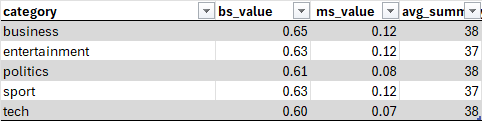              

As we see the table, the Berts scores were good but not optimal and Meteor scores were not good (lower than 0.12)indicating that maybe key phrases are missing. Also, the indicator of the summary length are quite similar (~37)words which is a sign that maybe they are too uniform, and this figure can not be possible due to Sports or Tech texts often use more numbers or metrics, than business or politics texts, implying that these lasts might need longer summaries.

2. Second evaluation

We decided to reavaluate the information, and we considered to elevate the limits per category, like 'business': 120, 'entertainment': 80, 'politics': 110,'sport': 60, and 'tech': 100. Also, we increase the limitis for the input length to 80% for max input, and 40% for min input, looking to adapat the summarization process to the varying sizes our texts have.
We obtain these results:

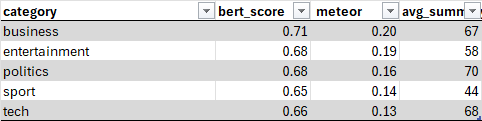

Within the Berts scores the higher values suggest better semantic similarity between the summarized text and the original text. The highest value is for business text with more than 0.71, and Sport being the lowest with 0.65, possibly due to the type of content being harder to summarize effectively.

While meteor metrics aims to match the summary with the original text in terms of both meaning and structure. Our biggest number is from Business (0.20), and the lowest is Tech with 0.134. But all categories are showing relatively low METEOR values, indicating that the summaries may not perfectly capture all aspects of the original text.

Average Summary Length: It varies across categories, with sport having the shortest summaries (~44 words), while business and tech have longer summaries (67 and 68 words respectively). This difference can be due to the nature of the text and the summarization logic.

And finally, the values of all categories have a ratio of 1.0, suggesting no data was missed or misallocated.


#In conclusion
Our summarization process performs well overall, but it might need some fine tuning to improve within specific topics like Sports or Tech.
To improve these results we suggest adjustments within the hyperparameters. Taking care of the batch and the model due to GPU memory in Colab environments. Also, manually evaluate a subset of summaries to identify patterns that could improve summarization quality.

#Sources

https://www.analyticsvidhya.com/blog/2018/11/introduction-text-summarization-textrank-python/

https://www.geeksforgeeks.org/text-summarization-in-nlp/

https://huggingface.co/facebook/bart-large-cnn

https://fabianofalcao.medium.com/metrics-for-evaluating-summarization-of-texts-performed-by-transformers-how-to-evaluate-the-b3ce68a309c3

https://spotintelligence.com/2024/08/26/meteor-metric-in-nlp-how-it-works-how-to-tutorial-in-python/#:~:text=One%20of%20the%20most%20significant,precision%20and%20n%2Dgram%20overlap.

https://www.linkedin.com/pulse/closer-look-bleu-metrics-challenges-best-practices-tg5lf/